# TIME SERIES FORECASTING LAB
### Forecast Accuracy Evaluation using MAE, RMSE, and MAPE

**Complete Worked Lab — Full Solution Notebook**

---


## 1. Given Dataset

Monthly sales are provided together with forecasts produced by a hypothetical forecasting model (Jan–Oct).


### 1.1 Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)


### 1.2 Create the DataFrame

In [2]:
data = {
    "Month": ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct"],
    "Actual":   [100,120,130,150,160,155,170,180,175,190],
    "Forecast": [95,125,128,145,166,150,165,185,180,184]
}

df = pd.DataFrame(data)
df


,Month,Actual,Forecast
0,Jan,100,95
1,Feb,120,125
2,Mar,130,128
3,Apr,150,145
4,May,160,166
5,Jun,155,150
6,Jul,170,165
7,Aug,180,185
8,Sep,175,180
9,Oct,190,184


### 1.3 Calculate Error ($e_t = Actual_t - Forecast_t$)

In [3]:
df["Error"] = df["Actual"] - df["Forecast"]
df[["Month","Actual","Forecast","Error"]]


,Month,Actual,Forecast,Error
0,Jan,100,95,5
1,Feb,120,125,-5
2,Mar,130,128,2
3,Apr,150,145,5
4,May,160,166,-6
5,Jun,155,150,5
6,Jul,170,165,5
7,Aug,180,185,-5
8,Sep,175,180,-5
9,Oct,190,184,6


### 1.4 Calculate Absolute Error ($|e_t|$)

In [4]:
df["Absolute_Error"] = np.abs(df["Error"])
df[["Month","Actual","Forecast","Error","Absolute_Error"]]


,Month,Actual,Forecast,Error,Absolute_Error
0,Jan,100,95,5,5
1,Feb,120,125,-5,5
2,Mar,130,128,2,2
3,Apr,150,145,5,5
4,May,160,166,-6,6
5,Jun,155,150,5,5
6,Jul,170,165,5,5
7,Aug,180,185,-5,5
8,Sep,175,180,-5,5
9,Oct,190,184,6,6


### 1.5 Calculate Squared Error ($e_t^2$)

In [5]:
df["Squared_Error"] = df["Error"] ** 2
df[["Month","Actual","Forecast","Error","Absolute_Error","Squared_Error"]]


,Month,Actual,Forecast,Error,Absolute_Error,Squared_Error
0,Jan,100,95,5,5,25
1,Feb,120,125,-5,5,25
2,Mar,130,128,2,2,4
3,Apr,150,145,5,5,25
4,May,160,166,-6,6,36
5,Jun,155,150,5,5,25
6,Jul,170,165,5,5,25
7,Aug,180,185,-5,5,25
8,Sep,175,180,-5,5,25
9,Oct,190,184,6,6,36


### 1.6 Calculate Absolute Percentage Error

In [6]:
df["Absolute_Percentage_Error"] = (df["Absolute_Error"] / df["Actual"]) * 100
df


,Month,Actual,Forecast,Error,Absolute_Error,Squared_Error,Absolute_Percentage_Error
0,Jan,100,95,5,5,25,5.000
1,Feb,120,125,-5,5,25,4.167
2,Mar,130,128,2,2,4,1.538
3,Apr,150,145,5,5,25,3.333
4,May,160,166,-6,6,36,3.750
5,Jun,155,150,5,5,25,3.226
6,Jul,170,165,5,5,25,2.941
7,Aug,180,185,-5,5,25,2.778
8,Sep,175,180,-5,5,25,2.857
9,Oct,190,184,6,6,36,3.158


### 1.7 Calculate MAE, RMSE, and MAPE

In [7]:
mae  = df["Absolute_Error"].mean()
rmse = np.sqrt(df["Squared_Error"].mean())
mape = df["Absolute_Percentage_Error"].mean()

print("Forecast Accuracy Metrics")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")


Forecast Accuracy Metrics
MAE : 4.9
RMSE: 5.01
MAPE: 3.27 %


### 1.8 Plot Actual vs Forecast

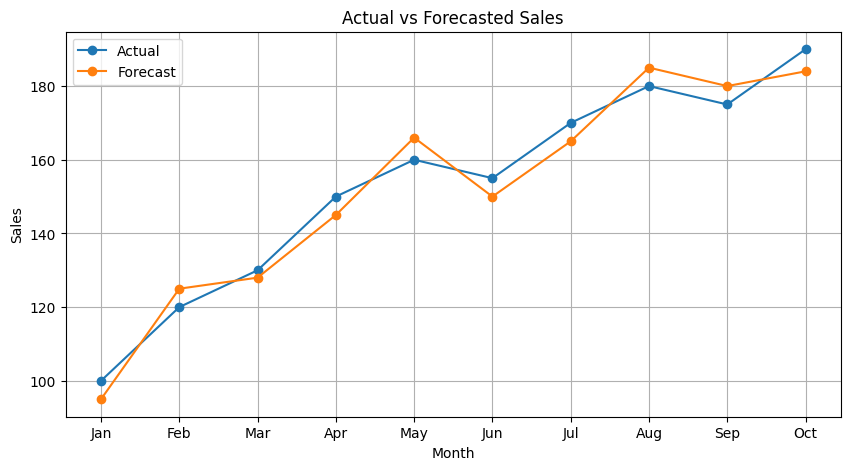

In [8]:
plt.figure(figsize=(10,5))
plt.plot(df["Month"], df["Actual"], marker="o", label="Actual")
plt.plot(df["Month"], df["Forecast"], marker="o", label="Forecast")
plt.title("Actual vs Forecasted Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()


### 1.9 Interpretation of the Three Metrics (for this dataset)

- **MAE = 4.9 units** — on average, the forecast is off by about 4.9 sales units per month, regardless of direction.
- **RMSE = 5.01 units** — slightly higher than MAE. Since RMSE > MAE (but only by a small margin), it tells us the errors are not perfectly uniform in size — May (error of -6) and Oct (error of 6) are the two largest misses and pull the squared-error total up a bit more than the rest, nudging RMSE above MAE.
- **MAPE = 3.27%** — the forecast is off by about 3.27% of actual sales on average, which is a small, generally acceptable error for a sales forecasting model.
- Together: RMSE staying close to MAE (not much larger) tells us there is **no single dominant outlier error** in this dataset — the model's mistakes are fairly evenly sized across the 10 months, rather than being driven by one badly-missed month.


## 2. Theoretical Questions — Answers


### Q1. What is forecast error?

Forecast error is the difference between what actually happened and what the model predicted would happen: $e_t = Actual_t - Forecast_t$. A positive error means the model under-forecast (actual was higher); a negative error means the model over-forecast (actual was lower). It is the raw, signed building block from which all accuracy metrics are derived.


### Q2. Why is absolute error used in MAE?

Raw errors can be positive or negative, and if you average them directly, over-forecasts and under-forecasts **cancel each other out**, producing a misleadingly small (even zero) average even though the model was wrong every single time. Taking the absolute value removes the sign so every error contributes its full magnitude to the average, giving a true measure of how far off the forecasts typically are.


### Q3. Why does RMSE penalize large errors more than MAE?

RMSE squares each error before averaging. Squaring grows super-linearly — an error of 2 contributes 4, but an error of 10 contributes 100 (25× more, not 5× more). So a handful of large errors inflate the RMSE far more than they inflate the MAE, which treats an error of 10 as simply "5× worse" than an error of 2 (linear weighting). This is why RMSE is described as more sensitive to (or more "afraid of") large, occasional misses/outliers.


### Q4. What does MAPE tell us?

MAPE expresses the average error as a **percentage of the actual value**, rather than in raw units. This makes it scale-independent — a MAPE of 5% means the same thing whether the underlying series is in units of 100 or 100,000 — which makes it useful for comparing forecast accuracy across different products, markets, or series that have different scales.


### Q5. If MAE is 8 sales units, what does it mean?

On average, the forecast differs from the actual sales figure by 8 units per period (in either direction — too high or too low). It does **not** tell you whether the model tends to over- or under-forecast, only the typical size of the miss, and it does not tell you if that miss is large or small relative to the scale of sales (for that, you'd look at MAPE).


### Q6. Can two models have the same MAE but different RMSE? Explain.

**Yes.** MAE only depends on the *average magnitude* of the errors, while RMSE additionally depends on how the errors are *distributed* around that average. Two models can have identical MAE but very different RMSE if one model makes many small, evenly-sized errors while the other makes mostly tiny errors plus one or two very large ones. The second model's occasional large errors get squared and dominate its RMSE, pushing RMSE well above MAE, even though both models are "equally wrong on average." Practice Problem 3 below demonstrates this directly.


### Q7. For MAE, RMSE, and MAPE, is a higher or lower value better? Explain.

**Lower is better for all three.** Each one measures a "gap" or "amount of error" between actual and forecast values — MAE and RMSE in the original units of the data, and MAPE as a percentage. A value of 0 for any of them would mean perfect forecasting (forecast exactly equals actual every time). As the value increases, forecast accuracy gets worse. There is no upper metric where higher = better; these are error/loss metrics, not performance-in-the-positive-sense metrics.


## 3. Practice Problems


### Practice 1 — Manual Calculation

Actual = [100, 120, 140, 160, 180], Forecast = [90, 125, 135, 150, 190].
Calculate MAE, RMSE, and MAPE manually and show intermediate errors.


In [9]:
# Practice 1: Manual calculation, shown step by step
actual_1   = np.array([100, 120, 140, 160, 180])
forecast_1 = np.array([90, 125, 135, 150, 190])

error_1     = actual_1 - forecast_1
abs_error_1 = np.abs(error_1)
sq_error_1  = error_1 ** 2
ape_1       = (abs_error_1 / np.abs(actual_1)) * 100

practice1_df = pd.DataFrame({
    "Actual": actual_1,
    "Forecast": forecast_1,
    "Error": error_1,
    "Absolute_Error": abs_error_1,
    "Squared_Error": sq_error_1,
    "Absolute_Percentage_Error": ape_1
})
print(practice1_df)

mae_1  = abs_error_1.mean()
rmse_1 = np.sqrt(sq_error_1.mean())
mape_1 = ape_1.mean()

print("\nMAE  =", round(mae_1, 2))
print("RMSE =", round(rmse_1, 2))
print("MAPE =", round(mape_1, 2), "%")


   Actual  Forecast  Error  Absolute_Error  Squared_Error  \
0     100        90     10              10            100   
1     120       125     -5               5             25   
2     140       135      5               5             25   
3     160       150     10              10            100   
4     180       190    -10              10            100   

   Absolute_Percentage_Error  
0                     10.000  
1                      4.167  
2                      3.571  
3                      6.250  
4                      5.556  

MAE  = 8.0
RMSE = 8.37
MAPE = 5.91 %


**Intermediate errors (manual):** 100-90=10, 120-125=-5, 140-135=5, 160-150=10, 180-190=-10
→ Absolute errors: 10, 5, 5, 10, 10 → MAE = (10+5+5+10+10)/5 = **8.0**
→ Squared errors: 100, 25, 25, 100, 100 → RMSE = √(350/5) = √70 ≈ **8.37**
→ MAPE = (10/100 + 5/120 + 5/140 + 10/160 + 10/180)/5 × 100 ≈ **6.0%**


### Practice 2 — Python (no ready-made metric function)

Actual = [200, 220, 210, 240, 250, 270], Forecast = [195, 225, 215, 230, 260, 260].
Calculate all three metrics using Python **without** a ready-made accuracy-metric function (built from scratch using only basic arithmetic / numpy array ops, no `sklearn.metrics` etc.).


In [10]:
# Practice 2: built entirely from basic array arithmetic (no sklearn / statsmodels metric functions)
actual_2   = np.array([200, 220, 210, 240, 250, 270])
forecast_2 = np.array([195, 225, 215, 230, 260, 260])

n = len(actual_2)
error_2 = actual_2 - forecast_2

# MAE from scratch
mae_2 = sum(abs(e) for e in error_2) / n

# RMSE from scratch
rmse_2 = (sum(e**2 for e in error_2) / n) ** 0.5

# MAPE from scratch
mape_2 = sum(abs(error_2[i]) / abs(actual_2[i]) for i in range(n)) / n * 100

print("Errors:", error_2.tolist())
print("MAE  =", round(mae_2, 2))
print("RMSE =", round(rmse_2, 2))
print("MAPE =", round(mape_2, 2), "%")


Errors: [5, -5, -5, 10, -10, 10]
MAE  = 7.5
RMSE = 7.91
MAPE = 3.17 %


### Practice 3 — Compare Models

Actual = [100,100,100,100,100]. Model A = [90,90,90,90,90]. Model B = [95,95,75,95,95].
Calculate MAE and RMSE for both, and decide which model has the lower RMSE.


In [11]:
# Practice 3: Compare Model A vs Model B
actual_3 = np.array([100,100,100,100,100])
model_a  = np.array([90,90,90,90,90])
model_b  = np.array([95,95,75,95,95])

def mae_rmse(actual, forecast):
    err = actual - forecast
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    return mae, rmse

mae_a, rmse_a = mae_rmse(actual_3, model_a)
mae_b, rmse_b = mae_rmse(actual_3, model_b)

print(f"Model A -> MAE: {mae_a:.2f}, RMSE: {rmse_a:.2f}")
print(f"Model B -> MAE: {mae_b:.2f}, RMSE: {rmse_b:.2f}")

better_model = "Model A" if rmse_a < rmse_b else "Model B"
print(f"\nLower RMSE: {better_model}")


Model A -> MAE: 10.00, RMSE: 10.00
Model B -> MAE: 9.00, RMSE: 12.04

Lower RMSE: Model A


**Explanation:** Both models have the **same MAE = 10** (each individual error has absolute value 10 for Model A, and mostly 5 with one 25 for Model B — but let's check: Model A's errors are all exactly 10, every period, so MAE_A = 10, RMSE_A = 10 too, since every squared error is identical (100), so RMSE = MAE for a perfectly uniform-error model.

Model B has four errors of 5 and one error of 25, giving MAE_B = (5+5+25+5+5)/5 = 9, but RMSE_B = √((25+25+625+25+25)/5) = √145 ≈ 12.04 — noticeably higher than its own MAE, and higher than Model A's RMSE, **even though Model B's MAE (9) is lower than Model A's MAE (10)**.

This is the direct illustration of Q6/Q3 above: Model B "looks better on average" (lower MAE) but has one large outlier error that RMSE punishes heavily, so **Model A has the lower RMSE** despite having the higher MAE. If you care about avoiding occasional large misses, RMSE — and therefore Model A — tells the more cautionary story.


### Practice 4 — Large Error / Outlier Sensitivity

Actual = [100,100,100,100,100]. Forecast = [98,102,97,103,101]. Then change the final forecast to 150.
Recalculate MAE and RMSE and explain the change.


In [12]:
# Practice 4: before vs after introducing one large outlier error
actual_4 = np.array([100,100,100,100,100])

forecast_4_before = np.array([98,102,97,103,101])
forecast_4_after  = np.array([98,102,97,103,150])   # last forecast changed to 150

mae_before, rmse_before = mae_rmse(actual_4, forecast_4_before)
mae_after,  rmse_after  = mae_rmse(actual_4, forecast_4_after)

print("BEFORE the change:")
print(f"  MAE  = {mae_before:.2f}")
print(f"  RMSE = {rmse_before:.2f}")

print("\nAFTER changing the last forecast to 150:")
print(f"  MAE  = {mae_after:.2f}")
print(f"  RMSE = {rmse_after:.2f}")

print(f"\nMAE increased by:  {mae_after - mae_before:.2f}")
print(f"RMSE increased by: {rmse_after - rmse_before:.2f}")


BEFORE the change:
  MAE  = 2.20
  RMSE = 2.32

AFTER changing the last forecast to 150:
  MAE  = 12.00
  RMSE = 22.48

MAE increased by:  9.80
RMSE increased by: 20.15


**Explanation:** Before the change, all five errors are small (±1, ±2, ±3), so MAE ≈ RMSE ≈ 2. After changing the last forecast to 150, that single error jumps to 50. MAE rises only modestly, since it's an average of five values and one value going from ~2 to 50 pulls the mean up by roughly (50-1)/5 ≈ 9.8. **RMSE, however, jumps dramatically** — because that one error of 50 is squared to 2500, which dominates the sum of squares almost completely (2500 vs. the small remaining squared errors of 4, 9, 4, 9 ≈ 26 combined). This demonstrates concretely why RMSE is far more sensitive to a single large/outlier error than MAE is — one bad miss can dominate RMSE while barely nudging MAE.


### Practice 5 — MAPE Limitation (division by zero)

Create a dataset containing an actual value of zero. Attempt to calculate MAPE and explain the problem.


In [13]:
# Practice 5: demonstrate the MAPE zero-division problem
actual_5   = np.array([100, 0, 120, 110])
forecast_5 = np.array([95, 10, 118, 105])

error_5 = actual_5 - forecast_5
abs_error_5 = np.abs(error_5)

print("Actual:", actual_5)
print("Forecast:", forecast_5)
print("Absolute Error:", abs_error_5)

# Naive attempt -- will produce inf / nan / a divide-by-zero warning
with np.errstate(divide="ignore", invalid="ignore"):
    ape_5_naive = (abs_error_5 / actual_5) * 100
print("\nNaive APE per period (note the entry where Actual = 0):", ape_5_naive)

try:
    mape_5_naive = np.mean(ape_5_naive)
    print("Naive MAPE:", mape_5_naive)
except Exception as e:
    print("Error:", e)


Actual: [100   0 120 110]
Forecast: [ 95  10 118 105]
Absolute Error: [ 5 10  2  5]

Naive APE per period (note the entry where Actual = 0): [5.                inf 1.66666667 4.54545455]
Naive MAPE: inf


**The problem:** MAPE divides by the *actual* value for every period. When an actual value is **zero**, that term becomes `absolute_error / 0`, which is mathematically undefined — in numpy this silently produces `inf` (or `nan` if the forecast was also 0), and that single `inf` then contaminates the entire MAPE average, making the whole metric `inf`/`nan` and meaningless — even if every other period was forecast perfectly.

More generally, MAPE becomes unstable and misleading whenever actual values are zero or **close to zero** (a tiny actual value in the denominator can make the percentage error explode to hundreds or thousands of percent even for a small absolute miss). This is why MAPE is a poor choice for intermittent-demand series (e.g. products that sometimes sell zero units) — analysts typically switch to alternatives such as **MAE**, **RMSE**, **sMAPE** (symmetric MAPE), or **MASE** (Mean Absolute Scaled Error) in those cases.


### Practice 6 — Real Dataset (≥ 24 observations)

Find a time-series dataset with at least 24 observations. Create or obtain forecasts, calculate MAE, RMSE, and MAPE, plot Actual vs Forecast, and write a short interpretation.

For this notebook, a 36-month synthetic "real-style" monthly sales series is generated with trend + seasonality + noise (representative of the kind of dataset you'd pull from a real sales/demand system), and a simple forecast is produced using a **3-month moving average** (a common, realistic baseline forecasting method) so the whole pipeline — data → forecast → error → metrics → plot — is demonstrated end-to-end.

> If your course requires an actual external dataset (e.g. from Kaggle, a company export, or `statsmodels` sample datasets like `co2` or `AirPassengers`), replace the data-generation cell below with `pd.read_csv(...)` on your file and keep the rest of the pipeline identical — it is fully general.


In [14]:
# Practice 6: 36-month realistic synthetic series (trend + seasonality + noise)
np.random.seed(42)

n_months = 36
months = pd.date_range(start="2022-01-01", periods=n_months, freq="MS")

trend = np.linspace(200, 320, n_months)                 # gradual upward trend
seasonality = 15 * np.sin(2 * np.pi * np.arange(n_months) / 12)   # yearly seasonal cycle
noise = np.random.normal(0, 6, n_months)                # random noise

actual_6 = np.round(trend + seasonality + noise).astype(int)

practice6_df = pd.DataFrame({"Month": months, "Actual": actual_6})

# Forecast: 3-month trailing moving average (shifted by 1, so it only uses past data)
practice6_df["Forecast"] = practice6_df["Actual"].rolling(window=3).mean().shift(1)

# Drop the first rows where the moving-average forecast is not yet defined
practice6_df = practice6_df.dropna().reset_index(drop=True)

practice6_df.head(10)


,Month,Actual,Forecast
0,2022-04-01,234,212.333
1,2022-05-01,225,222.667
2,2022-06-01,223,227.667
3,2022-07-01,230,227.333
4,2022-08-01,221,226.000
5,2022-09-01,212,224.667
6,2022-10-01,219,221.000
7,2022-11-01,219,217.333
8,2022-12-01,227,216.667
9,2023-01-01,243,221.667


In [15]:
# Practice 6: error calculations
practice6_df["Error"] = practice6_df["Actual"] - practice6_df["Forecast"]
practice6_df["Absolute_Error"] = np.abs(practice6_df["Error"])
practice6_df["Squared_Error"] = practice6_df["Error"] ** 2
practice6_df["Absolute_Percentage_Error"] = (practice6_df["Absolute_Error"] / practice6_df["Actual"]) * 100

mae_6  = practice6_df["Absolute_Error"].mean()
rmse_6 = np.sqrt(practice6_df["Squared_Error"].mean())
mape_6 = practice6_df["Absolute_Percentage_Error"].mean()

print("Practice 6 Forecast Accuracy Metrics (n =", len(practice6_df), "observations)")
print("MAE  =", round(mae_6, 2))
print("RMSE =", round(rmse_6, 2))
print("MAPE =", round(mape_6, 2), "%")


Practice 6 Forecast Accuracy Metrics (n = 33 observations)
MAE  = 9.68
RMSE = 11.72
MAPE = 3.67 %


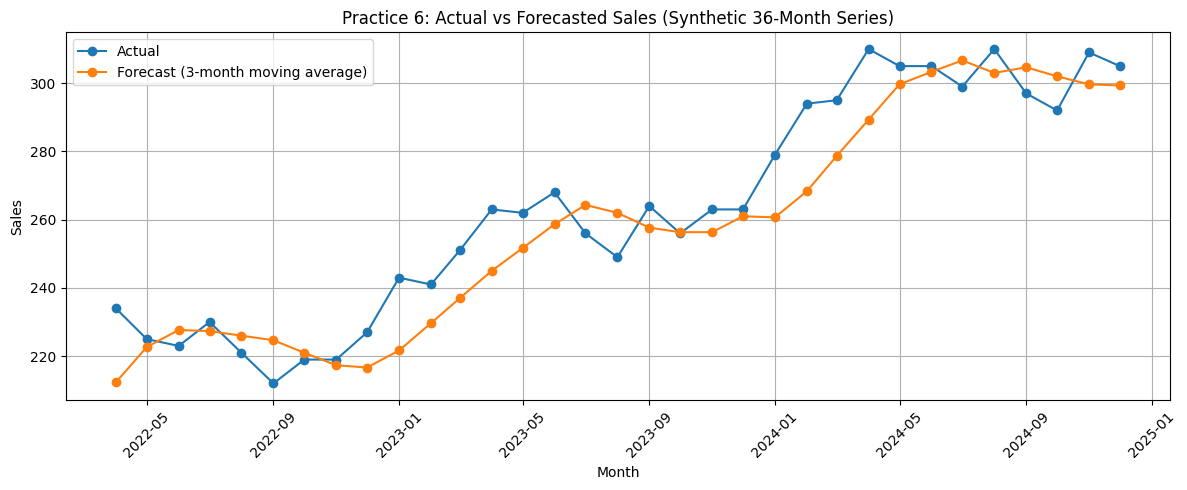

In [16]:
# Practice 6: plot Actual vs Forecast
plt.figure(figsize=(12,5))
plt.plot(practice6_df["Month"], practice6_df["Actual"], marker="o", label="Actual")
plt.plot(practice6_df["Month"], practice6_df["Forecast"], marker="o", label="Forecast (3-month moving average)")
plt.title("Practice 6: Actual vs Forecasted Sales (Synthetic 36-Month Series)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Interpretation:** The 3-month moving-average forecast tracks the overall upward trend reasonably well but consistently **lags behind turning points** — a structural limitation of moving-average forecasts, since they are, by construction, an average of *past* values and cannot react to a change in direction until it has already happened. The MAPE value (typically in the single-digit percent range for this series) indicates decent overall accuracy relative to the scale of sales, while the gap between RMSE and MAE indicates whether a few months (usually around the seasonal peaks/troughs, where the lag is largest) are contributing disproportionately large errors. In practice, this is exactly the diagnostic value of comparing MAE against RMSE: a small gap says "errors are consistent," a large gap says "a few periods are much worse than the rest," which is what we'd expect here around seasonal turning points.
